# Preço do combustível em 10 países (1990 a 2008)

**Pergunta:** como os preços evoluíram, e subir mais em porcentagem significa terminar mais caro?

Os valores estão em US$ nominais, sem ajuste pela inflação. A unidade de volume não está documentada na base.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

NOMES = {
    'Australia': 'Austrália', 'Canada': 'Canadá', 'France': 'França',
    'Germany': 'Alemanha', 'Italy': 'Itália', 'Japan': 'Japão',
    'Mexico': 'México', 'South Korea': 'Coreia do Sul',
    'UK': 'Reino Unido', 'USA': 'EUA',
}

plt.rcParams.update({'figure.figsize': (10, 5.5), 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Carga e qualidade dos dados

In [2]:
gas = pd.read_csv('gas_prices.csv').rename(columns={'Year': 'ano', **NOMES}).set_index('ano')
print(f'{gas.shape[0]} anos, {gas.shape[1]} países')
gas.isna().sum()[lambda faltantes: faltantes > 0]

19 anos, 10 países


Austrália    1
dtype: int64

O único valor ausente é o da Austrália em 1990. Ele não foi preenchido: a Austrália é medida a partir de 1991.

## 2. Evolução dos preços

Este é o gráfico do projeto original, corrigido. O nome `'Ytaly'` não existia na base, então a Itália não aparecia.

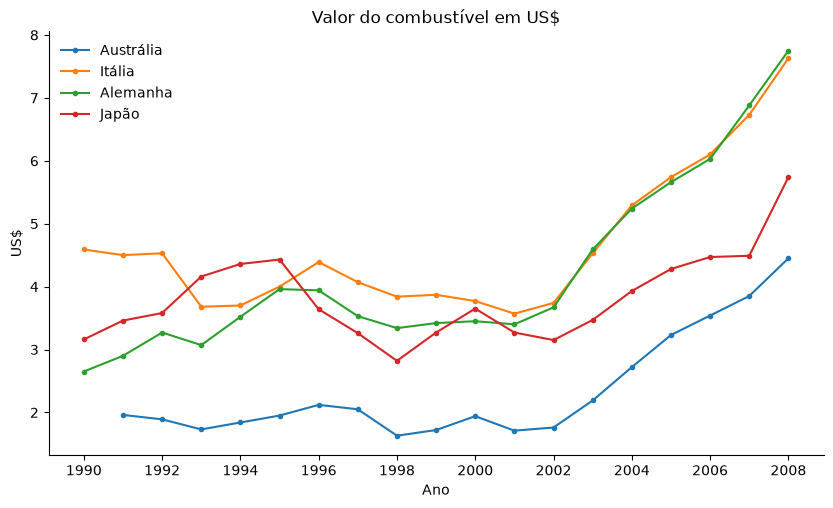

In [3]:
paises = ['Austrália', 'Itália', 'Alemanha', 'Japão']

fig, ax = plt.subplots()
for pais in paises:
    ax.plot(gas.index, gas[pais], marker='.', label=pais)

ax.set_title('Valor do combustível em US$')
ax.set_xlabel('Ano')
ax.set_ylabel('US$')
ax.set_xticks(gas.index[::2])
ax.legend(frameon=False)
fig.savefig('imagens/evolucao-precos.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Análise em SQL

A base foi passada para o formato longo e carregada em um SQLite em memória. As consultas estão em [`sql/consultas.sql`](sql/consultas.sql).

In [4]:
longo = gas.reset_index().melt('ano', var_name='pais', value_name='preco').dropna()

conexao = sqlite3.connect(':memory:')
longo.to_sql('precos', conexao, index=False)

consultas = [c for c in Path('sql/consultas.sql').read_text(encoding='utf-8').split(';') if c.strip()]
variacao, media_anual, mais_caros = [pd.read_sql(c, conexao) for c in consultas]
variacao

,pais,ano_inicial,preco_inicial,preco_final,variacao_pct,cagr_pct
0,Alemanha,1990,2.65,7.75,192.5,6.14
1,Coreia do Sul,1990,2.05,5.83,184.4,5.98
2,EUA,1990,1.16,3.27,181.9,5.93
3,Reino Unido,1990,2.82,7.42,163.1,5.52
4,México,1990,1.00,2.45,145.0,5.10
5,Austrália,1991,1.96,4.45,127.0,4.94
6,Canadá,1990,1.87,4.08,118.2,4.43
7,França,1990,3.63,7.51,106.9,4.12
8,Japão,1990,3.16,5.74,81.6,3.37
9,Itália,1990,4.59,7.63,66.2,2.86


In [5]:
media_anual.sort_values('variacao_media_pct').iloc[[0, 1, -3, -2, -1]]

,ano,variacao_media_pct
7,1998,-7.9
10,2001,-5.8
14,2005,13.2
12,2003,14.7
13,2004,14.8


In [6]:
mais_caros

,pais,anos_como_mais_caro
0,Reino Unido,10
1,Itália,4
2,Japão,3
3,França,1
4,Alemanha,1


## 4. Alta percentual ou preço final?

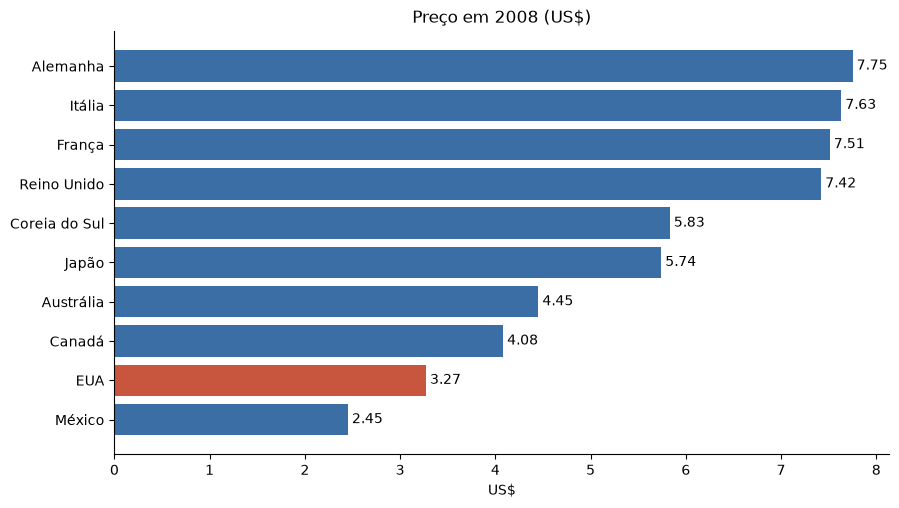

México           0.75
EUA              1.00
Canadá           1.25
Austrália        1.36
Japão            1.76
Coreia do Sul    1.78
Reino Unido      2.27
França           2.30
Itália           2.33
Alemanha         2.37
Name: 2008, dtype: float64

In [7]:
ultimo_ano = gas.loc[2008].sort_values()
relacao_eua = (ultimo_ano / ultimo_ano['EUA']).round(2)

fig, ax = plt.subplots()
cores = ['#c8553d' if pais == 'EUA' else '#3a6ea5' for pais in ultimo_ano.index]
barras = ax.barh(ultimo_ano.index, ultimo_ano.values, color=cores)
ax.bar_label(barras, labels=[f'{valor:.2f}' for valor in ultimo_ano.values], padding=3)
ax.set_title('Preço em 2008 (US$)')
ax.set_xlabel('US$')
fig.savefig('imagens/precos-2008.png', dpi=150, bbox_inches='tight')
plt.show()

relacao_eua

## 5. Conclusões

- **Alta:** a Alemanha subiu mais em porcentagem (+192,5%). A Itália, a mais cara de 1990, subiu menos (+66,2%).
- **Preço final:** os EUA tiveram a terceira maior alta (+181,9%), mas terminaram 2008 entre os mais baratos, porque partiram de US$ 1,16. A Alemanha custava 2,37 vezes o preço dos EUA.
- **Período:** a alta se concentrou em 2003 a 2005, com variação média de 13% a 15% ao ano. As maiores quedas médias foram em 1998 (-7,9%) e 2001 (-5,8%).
- **Liderança:** o Reino Unido foi o mais caro em 10 dos 19 anos.

**Limites:** os valores são nominais e em dólar, então inflação e câmbio afetam a comparação. A análise descreve o que aconteceu, sem explicar a causa. A origem da base não está registrada neste repositório.